# DHVC Ra = 1e7 — 최적화 전(원본 f330720) vs 후(현재) 통계 비교

`input_dhvc_1e7_val_{orig,new}.ini`: 832×416×192, npz 4 (V100 ×4, gpu19 / gpu18), 1e6 검증 런(t 240) 체크포인트를 같은 warm-start 로 써서 t 200 까지, 통계 창 **t 100~200** (누적 파일 125·150·175·200).
원본 = `build_gpu/bin/dhvc_validate_orig`(원본 코드 + 계측 main, 타이머 끔), 현재 = `dhvc_validate_new`. 두 런은 같은 초기장이지만 반올림 차이로 곧 다른 난류 실현으로 갈라지므로 **창 변동 안의 차이면 같은 통계**로 본다.
그림은 증거로 `docs/Scalability/validation/dhvc_1e7_*.png` 에 저장한다.

In [ ]:
import glob, re, os
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
SAVE_FIG = True
FIG_DIR = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), "docs", "Scalability", "validation"); os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    if SAVE_FIG: fig.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight"); print("saved", os.path.relpath(os.path.join(FIG_DIR, name), os.getcwd()))
COLS = ["z", "U", "V", "W", "T", "urms", "vrms", "wrms", "trms", "uw", "uT", "wT"]
STYLE = {"orig": dict(color="#9a9a96", ls="--", marker="o", mfc="white", ms=5, mew=1.2), "new": dict(color="#2a78d6", ls="-", marker="s", ms=3)}
def load(path):
    hdr, rows = {}, []
    for l in open(path):
        if l.startswith("#"):
            for k, v in re.findall(r"(\w+)=([-+0-9.eE]+)", l): hdr[k] = float(v)
        elif l.strip(): rows.append([float(x) for x in l.split()])
    return hdr, np.array(rows)
RUNS = {v: sorted(glob.glob(f"out_val_1e7_{v}/dhvc_stats_*.dat")) for v in ("orig", "new")}
FINAL = {v: load(f[-1]) for v, f in RUNS.items()}
SERIES = {v: [load(f)[0] for f in fs] for v, fs in RUNS.items()}
TITLE = "DHVC Ra 1e7, 832×416×192, V100 ×4 — window t 100–200"
print(f"{'quantity':16s} {'orig':>12s} {'new':>12s} {'diff':>8s}")
for k in ("Nu_hot", "Nu_cold", "u_tau_hot", "u_tau_cold", "Re_dstar", "Re_rms", "U_rms_delta_max", "delta_star", "delta_max"):
    a, b = FINAL["orig"][0][k], FINAL["new"][0][k]; print(f"{k:16s} {a:12.5g} {b:12.5g} {100*(b-a)/a:7.2f}%")

quantity                 orig          new     diff
Nu_hot                 13.896       13.928    0.23%
Nu_cold                13.861       13.945    0.60%
u_tau_hot            0.098133     0.097982   -0.15%
u_tau_cold           0.097997     0.097858   -0.14%
Re_dstar               23.246       23.089   -0.68%
Re_rms                 1048.5       1090.1    3.97%
U_rms_delta_max        0.2774      0.28842    3.97%
delta_star           0.011179     0.011158   -0.18%
delta_max            0.055963     0.055963    0.00%


## 1. 평균 프로파일 ⟨U⟩(z), ⟨T⟩(z) — 원본(○ 파선) vs 현재(■ 실선)

saved ../../docs/Scalability/validation/dhvc_1e7_mean_profiles.png


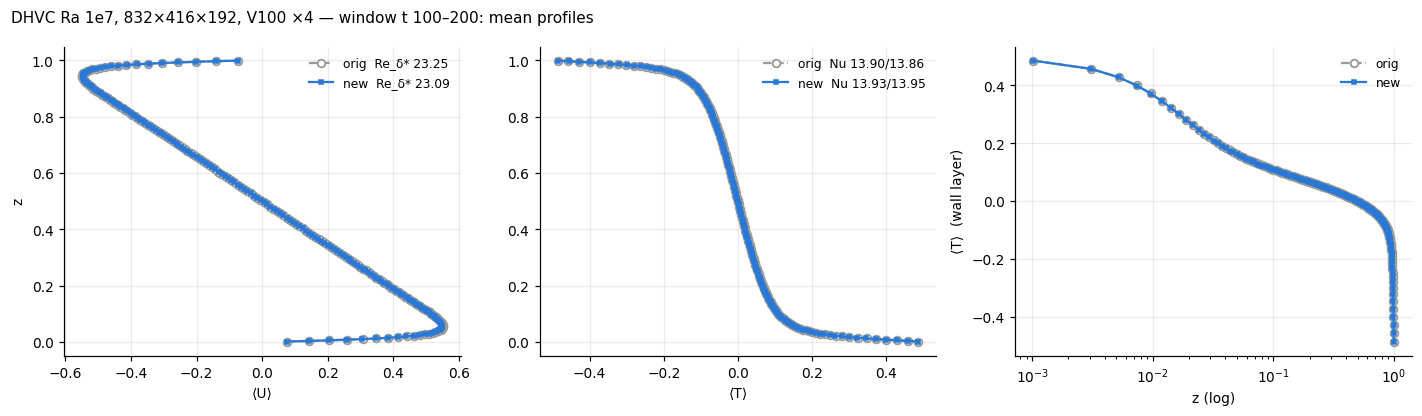

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for v in ("orig", "new"):
    h, d = FINAL[v]; z = d[:, 0]
    axes[0].plot(d[:, 1], z, label=f"{v}  Re_δ* {h['Re_dstar']:.2f}", **STYLE[v])
    axes[1].plot(d[:, 4], z, label=f"{v}  Nu {h['Nu_hot']:.2f}/{h['Nu_cold']:.2f}", **STYLE[v])
    axes[2].semilogx(z, d[:, 4], label=v, **STYLE[v])
axes[0].set_xlabel("⟨U⟩"); axes[0].set_ylabel("z"); axes[1].set_xlabel("⟨T⟩"); axes[2].set_xlabel("z (log)"); axes[2].set_ylabel("⟨T⟩  (wall layer)")
for ax in axes: ax.legend(frameon=False)
fig.suptitle(f"{TITLE}: mean profiles", x=0.01, ha="left", fontsize=10); fig.tight_layout(); save(fig, "dhvc_1e7_mean_profiles.png"); plt.show()

## 2. rms 프로파일 u·v·w·T

saved ../../docs/Scalability/validation/dhvc_1e7_rms_profiles.png


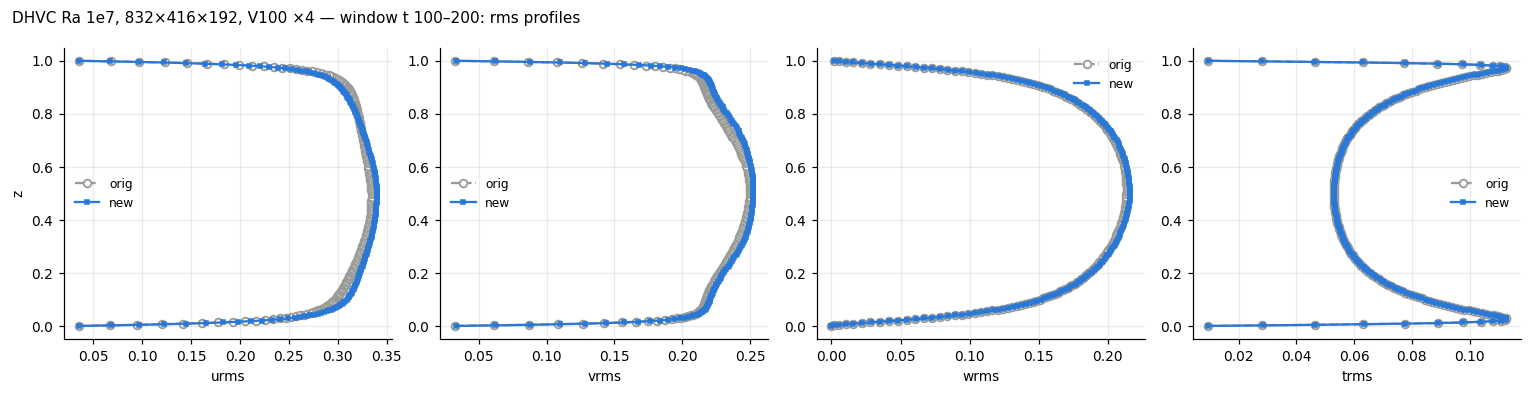

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for i, (ax, c) in enumerate(zip(axes, ("urms", "vrms", "wrms", "trms"))):
    for v in ("orig", "new"):
        d = FINAL[v][1]; ax.plot(d[:, 5 + i], d[:, 0], label=v, **STYLE[v])
    ax.set_xlabel(c); ax.set_ylabel("z" if i == 0 else ""); ax.legend(frameon=False)
fig.suptitle(f"{TITLE}: rms profiles", x=0.01, ha="left", fontsize=10); fig.tight_layout(); save(fig, "dhvc_1e7_rms_profiles.png"); plt.show()

## 3. 플럭스 ⟨u'w'⟩, ⟨u'T'⟩, ⟨w'T'⟩

saved ../../docs/Scalability/validation/dhvc_1e7_fluxes.png


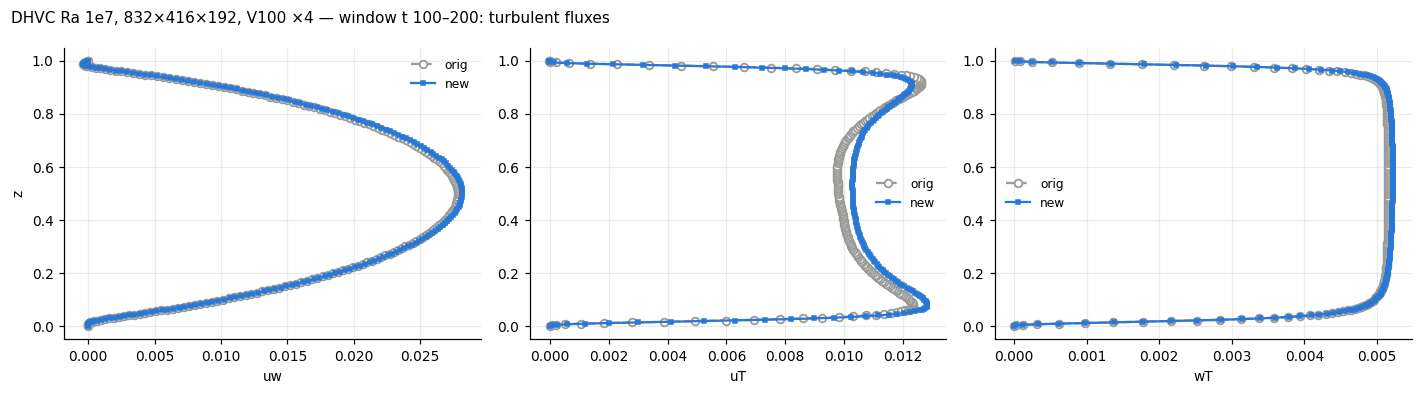

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for i, (ax, c) in enumerate(zip(axes, ("uw", "uT", "wT"))):
    for v in ("orig", "new"):
        d = FINAL[v][1]; ax.plot(d[:, 9 + i], d[:, 0], label=v, **STYLE[v])
    ax.set_xlabel(c); ax.set_ylabel("z" if i == 0 else ""); ax.legend(frameon=False)
fig.suptitle(f"{TITLE}: turbulent fluxes", x=0.01, ha="left", fontsize=10); fig.tight_layout(); save(fig, "dhvc_1e7_fluxes.png"); plt.show()

## 4. 누적 창(100 → t)에 따른 Nu·Re 수렴 — 창 변동 폭이 전/후 차이의 척도

saved ../../docs/Scalability/validation/dhvc_1e7_convergence.png
profile max|diff|/max|orig|: U 0.52%, T 0.21%, urms 3.67%, vrms 2.83%, wrms 1.20%, trms 0.35%, uw 1.28%, wT 1.30%


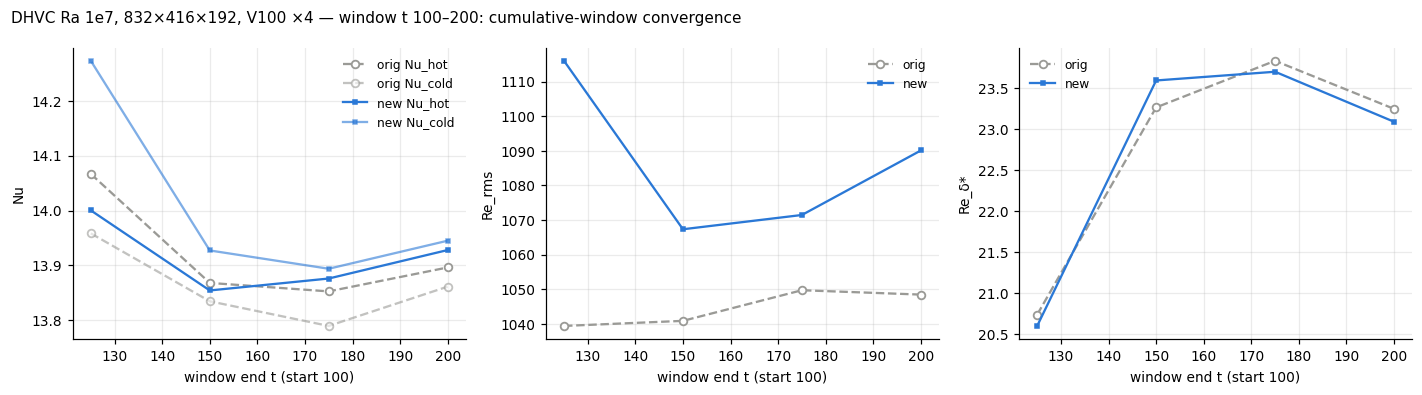

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for v in ("orig", "new"):
    t = [h["t_start"] + h["sum_dt"] for h in SERIES[v]]
    axes[0].plot(t, [h["Nu_hot"] for h in SERIES[v]], label=f"{v} Nu_hot", **STYLE[v])
    axes[0].plot(t, [h["Nu_cold"] for h in SERIES[v]], label=f"{v} Nu_cold", alpha=0.6, **STYLE[v])
    axes[1].plot(t, [h["Re_rms"] for h in SERIES[v]], label=v, **STYLE[v])
    axes[2].plot(t, [h["Re_dstar"] for h in SERIES[v]], label=v, **STYLE[v])
axes[0].set_ylabel("Nu"); axes[1].set_ylabel("Re_rms"); axes[2].set_ylabel("Re_δ*")
for ax in axes: ax.set_xlabel("window end t (start 100)"); ax.legend(frameon=False)
fig.suptitle(f"{TITLE}: cumulative-window convergence", x=0.01, ha="left", fontsize=10); fig.tight_layout(); save(fig, "dhvc_1e7_convergence.png"); plt.show()
print("profile max|diff|/max|orig|:", ", ".join(f"{c} {100*np.max(np.abs(FINAL['new'][1][:, i]-FINAL['orig'][1][:, i]))/max(np.max(np.abs(FINAL['orig'][1][:, i])), 1e-300):.2f}%" for i, c in enumerate(COLS) if c in ("U", "T", "urms", "vrms", "wrms", "trms", "uw", "wT")))